# NOTE
1: Dropped columns (no predictive value)

- `CustomerID`, `Count`: unique identifier / constant value.
- `Country`, `State`: single constant value (United States / California).
- `City`, `Zip Code`: too many unique values, would add many useless columns after encoding.
- `Lat Long`, `Latitude`, `Longitude`: raw location coordinates, with `Lat Long` duplicating the other two.

 2: Dropped columns (data leakage)

- `Churn Label`: duplicate of the target (`Churn Value` is kept as the target).
- `Churn Reason`: only known after the customer has left.
- `Churn Score`: output of another churn-prediction model.
- `CLTV`: derived value that may depend on churn and is unknown for a new customer.


3: Total Charges fix

- `Total Charges` was read as `object` because 11 rows contained a blank string instead of a number.
- All 11 rows have `Tenure Months = 0` (new customers not yet billed), so they were filled with 0 and the column was converted to `float64`.

 4: Data quality checks

- No missing values in any column (after the `Total Charges` fix).
- No duplicate customers (checked on `CustomerID` before dropping it).
- All categorical columns have clean, consistent values, with no typos or stray spaces.
- `No internet service` and `No phone service` are valid categories, not errors. They are redundant with `Internet Service` and `Phone Service`, so merging them with `No` is an option at the encoding step.

 5: Categorical features vs churn

- Overall churn rate is 26.5%; the data is imbalanced (about 73/27).
- `Contract` is the strongest signal: month-to-month ~43%, one year ~11%, two year ~3%.
- Churn is higher for customers with no partner, no dependents, and senior citizens.
- Fiber optic customers churn much more (~42%) than DSL (~19%).
- Customers without Online Security, Online Backup, Device Protection, or Tech Support churn much more than those who have them.
- Electronic check payers (~45%) and paperless billing customers (~33%) churn more.
- `Gender` and `Phone Service` show almost no difference, so they are weak features. Streaming TV/Movies and Multiple Lines show only small differences.
- `No internet service` / `No phone service` are redundant with `Internet Service` and `Phone Service`, and can be merged with `No` at the encoding step.
- These are correlations, not proof of cause.


 6: Numerical features vs churn

- `Tenure Months`: churners leave early (median 10 months vs 38 for retained customers). The first months are the highest-risk period.
- `Monthly Charges`: churners pay more (median 79.65 vs 64.43). Cheap plans (around 20) are mostly retained customers.
- `Total Charges`: churners have lower totals (median 703.55 vs 1,679.52), mostly because they stay for fewer months. It overlaps heavily with `Tenure Months` and `Monthly Charges`.
- The high `Total Charges` points among churners are valid long-tenure customers, not errors, so they are kept.
- Typical churner profile: new customer, month-to-month contract, high monthly bill.


 7: Train/Test split

- Data split 80/20 with `stratify=y` and `random_state=42`.
- Churn rate is preserved in both sets (about 26.5%), which matters because the data is imbalanced.
- The split is done before any encoding or scaling, so anything learned from the data is learned from the training set only.

8: Preprocessing

- Numerical columns (`Tenure Months`, `Monthly Charges`, `Total Charges`) are scaled with `StandardScaler`.
- 16 categorical columns are encoded with `OneHotEncoder(handle_unknown="ignore")`, giving 46 features in total.
- Both transformers are fitted on the training set only and then applied to the test set, which avoids data leakage.
- `No internet service` / `No phone service` are kept as separate categories for now; merging them with `No` can be tested later.

9: Baseline models (no class balancing)

- All three models perform similarly; accuracy is only slightly above the 0.735 majority-class baseline, so it is not a reliable metric here.
- Recall is the main weakness: every model misses about half of the customers who actually churn.
- Likely cause: the data is imbalanced (about 73/27) and no balancing was applied yet.
- Next step: retrain with `class_weight="balanced"` and compare.

10: Models with class_weight="balanced"


- Balancing raised Recall sharply for Logistic Regression and Decision Tree (about 0.57-0.60 to about 0.78-0.79) at the cost of Precision (about 0.64 to about 0.51).
- AUC-ROC stayed almost unchanged, so the models did not become better at ranking customers; the decision threshold effectively moved toward predicting churn more often.
- Random Forest was barely affected, since its deep trees fit the training data regardless of class weights.
- Accuracy dropped, which is expected and acceptable because it is not the main metric here.

11: Random Forest tuning

- Tuned `max_depth` and `min_samples_leaf` with `GridSearchCV` (5-fold, scoring F1) on the training set only, so the test set stayed untouched.
- Best parameters: `max_depth=12`, `min_samples_leaf=5` (CV F1 = 0.652).
- Recall rose from 0.516 to 0.746 and AUC-ROC from 0.833 to 0.854 compared with the untuned forest.
- CV F1 (0.652) and test F1 (0.636) are close, so there is no sign of overfitting.
- The best `max_depth` was the largest value in the grid, so a larger value could be tested.

 12: Final model comparison (test set, 1409 customers, 374 churners)
- The models catch about 75-79% of churners, but roughly one alert in two is a false alarm (Precision about 0.5).
- Even so, contacting the customers the model flags reaches about 51-55% real churners, versus about 26.5% when contacting customers at random.
- The high false-alarm count is the cost of `class_weight="balanced"`, which trades Precision for Recall.
- Accuracy is not used for selection: a model that predicts "no churn" for everyone scores 0.735.

13: Model comparison with cross-validation

- The ROC curves of the three models almost overlap (AUC about 0.84-0.85 on the test set), so no model is clearly better at ranking customers.
- A difference of 0.005 in AUC on 1,409 test customers can be chance, so the models were compared with 5-fold stratified cross-validation on the training set (mean ± std):

| Model | AUC-ROC | F1 | Recall | Precision |
|---|---|---|---|---|
| Logistic Regression | 0.859 ± 0.012 | 0.640 ± 0.021 | 0.810 ± 0.034 | 0.529 ± 0.020 |
| Decision Tree | 0.845 ± 0.008 | 0.629 ± 0.007 | 0.813 ± 0.022 | 0.514 ± 0.014 |
| Random Forest (tuned) | 0.860 ± 0.008 | 0.648 ± 0.021 | 0.751 ± 0.030 | 0.571 ± 0.021 |

- AUC and F1 differences are within the error margin, so the models have similar predictive quality. This is common on tabular data with mostly near-linear relationships.
- The only real difference is the operating point: Random Forest has lower Recall and higher Precision, while the other two catch more churners and raise more false alarms. This depends on the decision threshold (0.5 here), not only on the model.
- Caveats: Random Forest was tuned and the others were not, and its hyperparameters were chosen on the same training set, so its CV scores are slightly optimistic.


 14: Logistic Regression coefficients


- Strongest drivers (scaled numeric features, one-hot categoricals):
  - `Tenure Months` (-1.21): longer tenure lowers churn risk the most.
  - `Contract`: two-year (-0.75) lowers risk, month-to-month (+0.66) raises it.
  - `Internet Service`: fiber optic (+0.59) raises risk, DSL (-0.56) lowers it.
  - `Dependents`: customers with dependents are much less likely to churn.
- This confirms the patterns seen in the EDA.
- Paired one-hot columns (e.g. Dependents Yes/No) share one effect and should be read together.
- `Internet Service_No` and `Online Security_No internet service` have identical coefficients because they are the same column, confirming the redundancy noted earlier.
- `Monthly Charges` and `Total Charges` coefficients are not directly comparable with the EDA, because both are strongly correlated with `Tenure Months` and with the service columns.
- Coefficients describe association in the model, not causation.

### RESULT
Logistic Regression was selected because the three models perform equally well in cross-validation (AUC-ROC about 0.85-0.86, F1 about 0.63-0.65), so the choice rests on other criteria: it has the highest Recall (about 0.81), which matters most when missing a churner is costly, and it is the simplest to interpret and deploy.
Random Forest has higher Precision (fewer false alarms) but lower Recall, a difference in operating point rather than in model quality.

# Import necessart libraries

In [62]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import cross_validate, StratifiedKFold

# Exploring data & Preprocessing

In [3]:
data = pd.read_excel("Telco_customer_churn.xlsx")

In [4]:
data.sample(8)

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
3795,6384-VMJHP,1,United States,California,Bethel Island,94511,"38.050558, -121.646924",38.050558,-121.646924,Female,...,Two year,Yes,Credit card (automatic),73.00,5265.2,No,0,80,5127,NaN
6628,4726-DLWQN,1,United States,California,Live Oak,95953,"39.258746, -121.77697",39.258746,-121.776970,Male,...,Month-to-month,Yes,Bank transfer (automatic),70.35,3454.6,No,0,30,5596,NaN
1192,0378-TOVMS,1,United States,California,Vernalis,95385,"37.609095, -121.263381",37.609095,-121.263381,Female,...,Month-to-month,No,Electronic check,85.80,272.2,Yes,1,89,5641,Extra data charges
6784,0305-SQECB,1,United States,California,Gardena,90248,"33.876482, -118.284077",33.876482,-118.284077,Female,...,One year,Yes,Mailed check,36.05,402.6,No,0,67,4265,NaN
4255,3567-PQTSO,1,United States,California,Junction City,96048,"40.913192, -123.06597",40.913192,-123.065970,Male,...,One year,Yes,Electronic check,105.25,5576.3,No,0,56,6365,NaN
4997,6481-LXPWL,1,United States,California,Palo Alto,94306,"37.416159, -122.131337",37.416159,-122.131337,Male,...,One year,Yes,Credit card (automatic),36.10,1971.5,No,0,38,5092,NaN
33,0390-DCFDQ,1,United States,California,Los Alamitos,90720,"33.79499, -118.065591",33.794990,-118.065591,Female,...,Month-to-month,Yes,Mailed check,70.45,70.45,Yes,1,76,3964,Don't know
518,8901-HJXTF,1,United States,California,Oceanside,92057,"33.254497, -117.285879",33.254497,-117.285879,Female,...,Month-to-month,No,Mailed check,29.20,309.1,Yes,1,94,3747,Moved


In [7]:
data[["Country", "State"]].nunique()

Country    1
State      1
dtype: int64

In [12]:
cols_to_drop = [
    "CustomerID", "Count", "Country", "State", "City", "Zip Code",
    "Lat Long", "Latitude", "Longitude",
    "Churn Label", "Churn Reason", "Churn Score", "CLTV",
]

data_clean = data.drop(columns=cols_to_drop)
print(data_clean.shape)
data_clean.columns

(7043, 20)


Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value'],
      dtype='object')

In [13]:
data_clean.sample(5)

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value
6043,Female,No,Yes,Yes,64,No,No phone service,DSL,No,Yes,Yes,Yes,No,Yes,Two year,No,Electronic check,49.85,3210.35,0
5727,Male,No,Yes,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Electronic check,21.15,306.05,0
1070,Male,No,No,No,1,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,19.75,19.75,1
4366,Female,No,No,No,7,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.65,155.9,0
4402,Male,No,No,No,61,Yes,Yes,Fiber optic,Yes,Yes,Yes,No,Yes,Yes,One year,Yes,Electronic check,107.75,6521.9,0


In [10]:
data_clean.columns

Index(['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months',
       'Phone Service', 'Multiple Lines', 'Internet Service',
       'Online Security', 'Online Backup', 'Device Protection', 'Tech Support',
       'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing',
       'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value'],
      dtype='object')

In [15]:
data_clean.dtypes

Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges         object
Churn Value            int64
dtype: object

In [17]:
problem = data_clean[pd.to_numeric(data_clean["Total Charges"], errors="coerce").isna()]
print(len(problem))
problem[["Tenure Months", "Monthly Charges", "Total Charges"]]

11


,Tenure Months,Monthly Charges,Total Charges
2234,0,52.55,
2438,0,20.25,
2568,0,80.85,
2667,0,25.75,
2856,0,56.05,
4331,0,19.85,
4687,0,25.35,
5104,0,20.00,
5719,0,19.70,
6772,0,73.35,


In [18]:
data_clean["Total Charges"] = pd.to_numeric(data_clean["Total Charges"], errors="coerce").fillna(0)
data_clean["Total Charges"].dtype

dtype('float64')

In [19]:
data_clean.dtypes

Gender                object
Senior Citizen        object
Partner               object
Dependents            object
Tenure Months          int64
Phone Service         object
Multiple Lines        object
Internet Service      object
Online Security       object
Online Backup         object
Device Protection     object
Tech Support          object
Streaming TV          object
Streaming Movies      object
Contract              object
Paperless Billing     object
Payment Method        object
Monthly Charges      float64
Total Charges        float64
Churn Value            int64
dtype: object

In [20]:
data_clean.isna().sum()

Gender               0
Senior Citizen       0
Partner              0
Dependents           0
Tenure Months        0
Phone Service        0
Multiple Lines       0
Internet Service     0
Online Security      0
Online Backup        0
Device Protection    0
Tech Support         0
Streaming TV         0
Streaming Movies     0
Contract             0
Paperless Billing    0
Payment Method       0
Monthly Charges      0
Total Charges        0
Churn Value          0
dtype: int64

In [21]:
data["CustomerID"].duplicated().sum()

np.int64(0)

In [22]:
for col in data_clean.select_dtypes(include="object").columns:
    print(col, data_clean[col].unique())

Gender ['Male' 'Female']
Senior Citizen ['No' 'Yes']
Partner ['No' 'Yes']
Dependents ['No' 'Yes']
Phone Service ['Yes' 'No']
Multiple Lines ['No' 'Yes' 'No phone service']
Internet Service ['DSL' 'Fiber optic' 'No']
Online Security ['Yes' 'No' 'No internet service']
Online Backup ['Yes' 'No' 'No internet service']
Device Protection ['No' 'Yes' 'No internet service']
Tech Support ['No' 'Yes' 'No internet service']
Streaming TV ['No' 'Yes' 'No internet service']
Streaming Movies ['No' 'Yes' 'No internet service']
Contract ['Month-to-month' 'Two year' 'One year']
Paperless Billing ['Yes' 'No']
Payment Method ['Mailed check' 'Electronic check' 'Bank transfer (automatic)'
 'Credit card (automatic)']


Churn Value
0    5174
1    1869
Name: count, dtype: int64
Churn Value
0    0.73463
1    0.26537
Name: proportion, dtype: float64


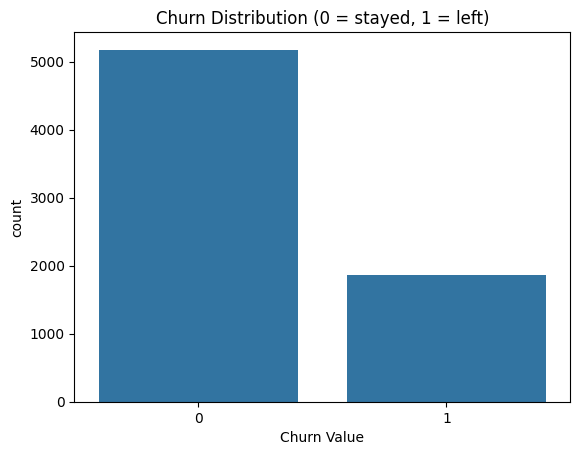

In [24]:
print(data_clean["Churn Value"].value_counts())
print(data_clean["Churn Value"].value_counts(normalize=True))

sns.countplot(x="Churn Value", data=data_clean)
plt.title("Churn Distribution (0 = stayed, 1 = left)")
plt.show()

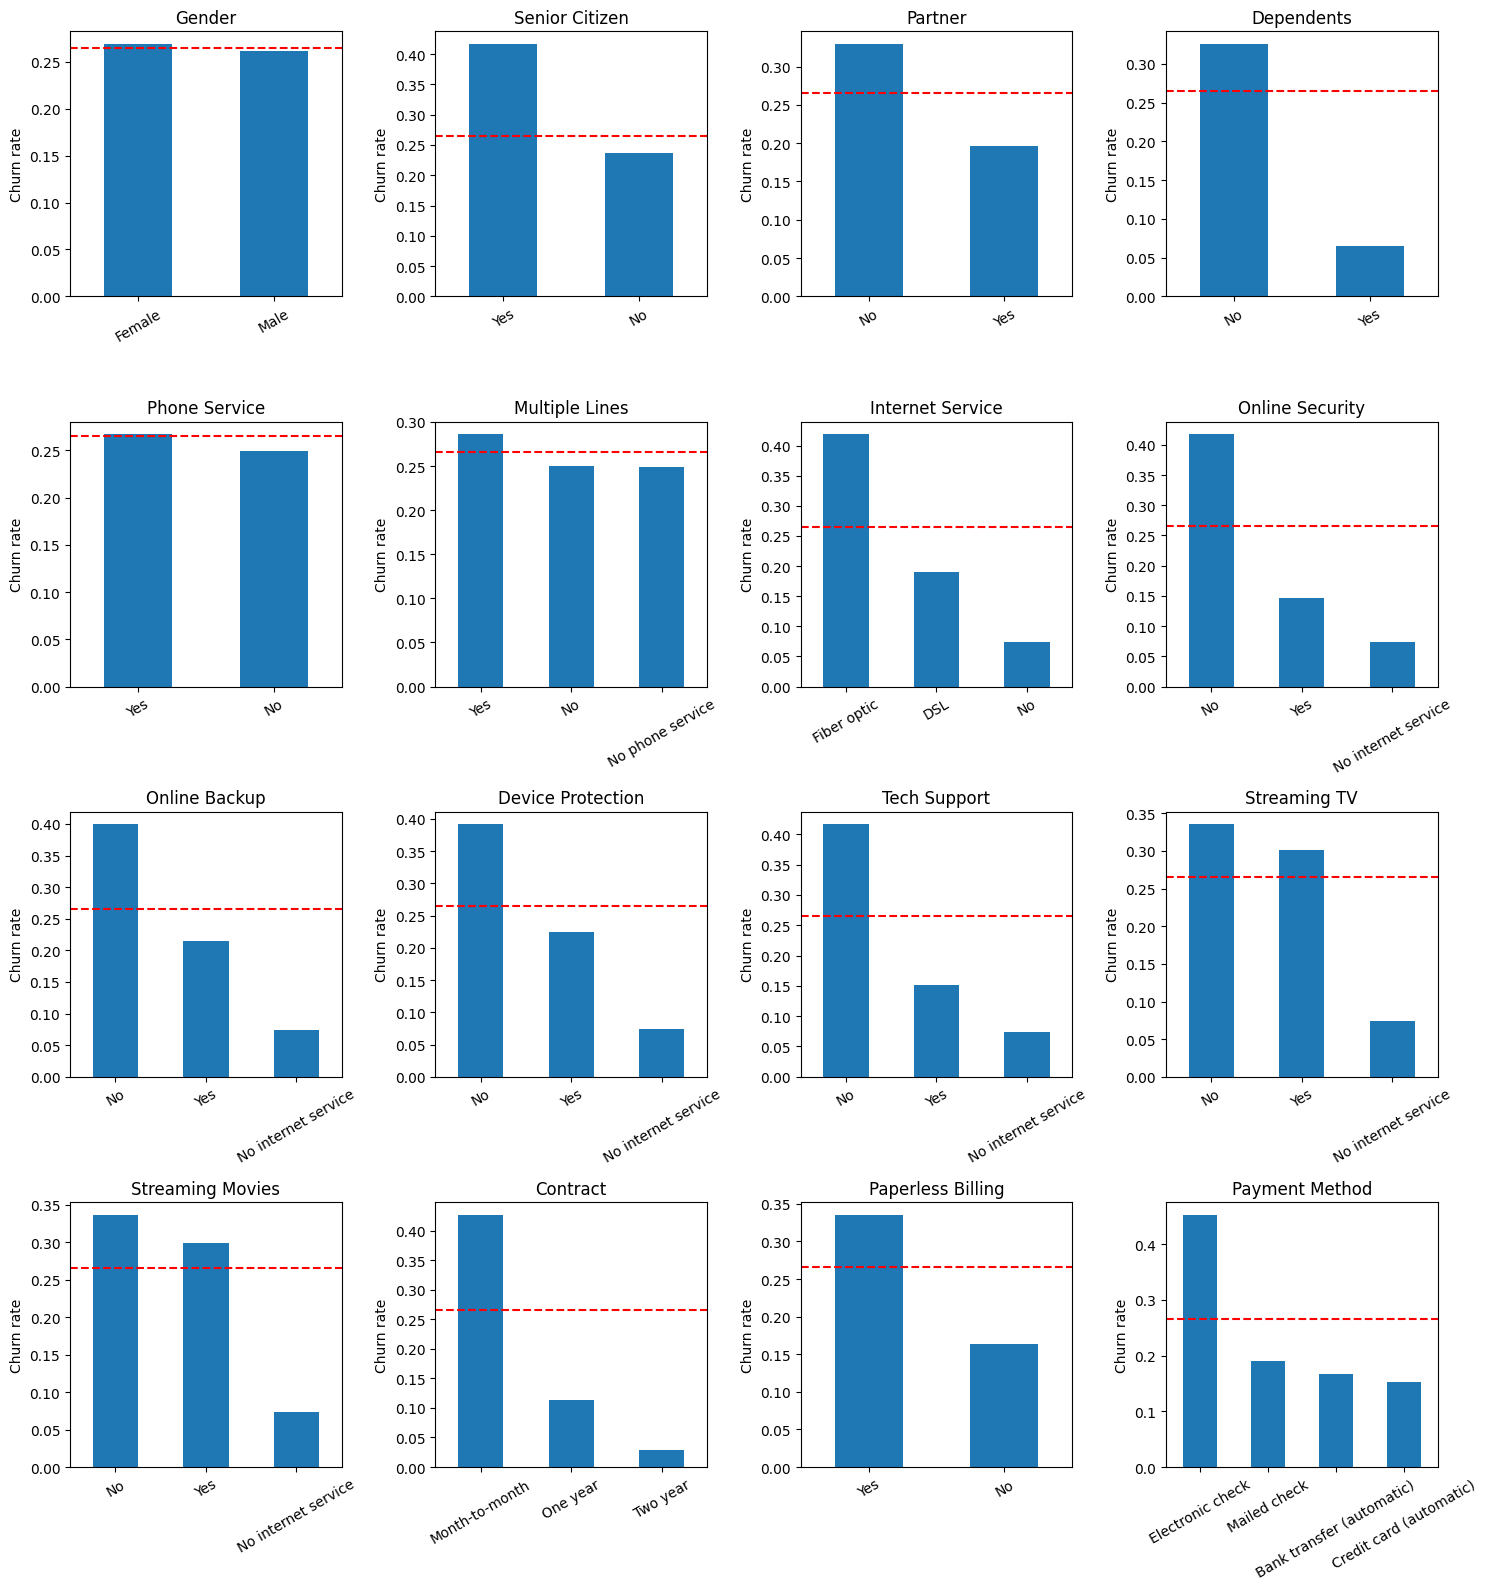

In [33]:
cat_cols = data_clean.select_dtypes(include="object").columns
overall = data_clean["Churn Value"].mean()

n_cols = 4
n_rows = -(-len(cat_cols) // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cat_cols):
    rate = data_clean.groupby(col)["Churn Value"].mean().sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax)
    ax.axhline(overall, color="red", linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Churn rate")
    ax.tick_params(axis="x", rotation=30)

for ax in axes[len(cat_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


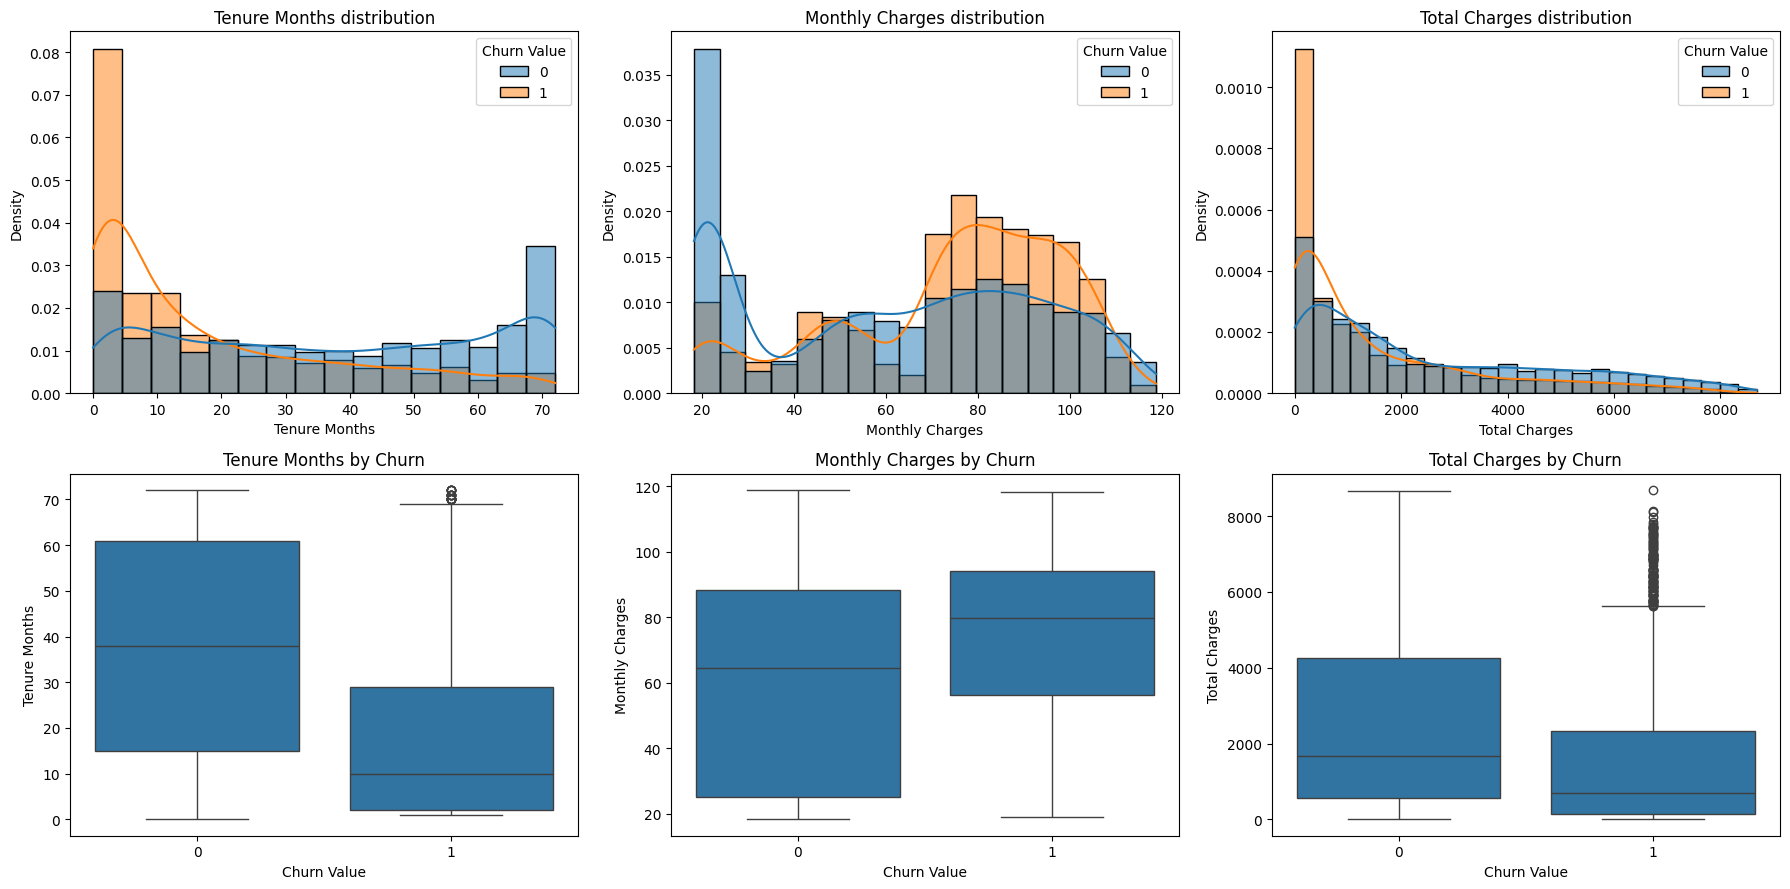

In [34]:
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]

fig, axes = plt.subplots(2, 3, figsize=(18, 9))

for i, col in enumerate(num_cols):
    sns.histplot(data=data_clean, x=col, hue="Churn Value", kde=True, stat="density", common_norm=False, ax=axes[0, i])
    axes[0, i].set_title(f"{col} distribution")
    
    sns.boxplot(data=data_clean, x="Churn Value", y=col, ax=axes[1, i])
    axes[1, i].set_title(f"{col} by Churn")

plt.tight_layout()
plt.show()

In [35]:
print(data_clean.groupby("Churn Value")[num_cols].mean().round(2))
print(data_clean.groupby("Churn Value")[num_cols].median().round(2))

             Tenure Months  Monthly Charges  Total Charges
Churn Value                                               
0                    37.57            61.27        2549.91
1                    17.98            74.44        1531.80
             Tenure Months  Monthly Charges  Total Charges
Churn Value                                               
0                     38.0            64.43        1679.52
1                     10.0            79.65         703.55


## TRAIN & TEST

In [37]:
X = data_clean.drop(columns=["Churn Value"])
y = data_clean["Churn Value"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(5634, 19) (1409, 19)
0.2653532126375577 0.2654364797728886


In [40]:
num_cols = ["Tenure Months", "Monthly Charges", "Total Charges"]
cat_cols = X_train.select_dtypes(include="object").columns.tolist()

print(len(num_cols), len(cat_cols))

3 16


In [41]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

In [42]:
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print(X_train_prep.shape, X_test_prep.shape)

(5634, 46) (1409, 46)


In [44]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

pipelines = {}
for name, model in models.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", model),
    ])
    pipe.fit(X_train, y_train)
    pipelines[name] = pipe
    print(name, "trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained


In [48]:
results = []
for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_proba),
    })

results_data = pd.DataFrame(results).set_index("Model").round(3)
results_data

,Accuracy,Precision,Recall,F1,AUC-ROC
Model,,,,,
Logistic Regression,0.802,0.644,0.570,0.604,0.849
Decision Tree,0.794,0.616,0.596,0.606,0.835
Random Forest,0.795,0.641,0.516,0.572,0.833


In [49]:
models_bal = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42),
}

results_bal = []
pipelines_bal = {}
for name, model in models_bal.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pipelines_bal[name] = pipe

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    results_bal.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_proba),
    })

results_bal_data = pd.DataFrame(results_bal).set_index("Model").round(3)
results_bal_data

,Accuracy,Precision,Recall,F1,AUC-ROC
Model,,,,,
Logistic Regression,0.743,0.510,0.781,0.617,0.849
Decision Tree,0.740,0.506,0.791,0.617,0.841
Random Forest,0.792,0.633,0.516,0.568,0.832


In [51]:
from sklearn.metrics import confusion_matrix

for name, pipe in pipelines_bal.items():
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    print(name)
    print(cm)

Logistic Regression
[[755 280]
 [ 82 292]]
Decision Tree
[[746 289]
 [ 78 296]]
Random Forest
[[923 112]
 [181 193]]


In [53]:
rf_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)),
])

param_grid = {
    "model__max_depth": [5, 8, 12],
    "model__min_samples_leaf": [1, 5, 10],
}

grid = GridSearchCV(rf_pipe, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

print(grid.best_params_)
print(round(grid.best_score_, 3))

{'model__max_depth': 12, 'model__min_samples_leaf': 5}
0.652


In [54]:
best_rf = grid.best_estimator_

y_pred = best_rf.predict(X_test)
y_proba = best_rf.predict_proba(X_test)[:, 1]

pd.DataFrame([{
    "Model": "Random Forest (tuned)",
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall": recall_score(y_test, y_pred),
    "F1": f1_score(y_test, y_pred),
    "AUC-ROC": roc_auc_score(y_test, y_proba),
}]).set_index("Model").round(3)

,Accuracy,Precision,Recall,F1,AUC-ROC
Model,,,,,
Random Forest (tuned),0.773,0.554,0.746,0.636,0.854


In [61]:
final_models = {
    "Logistic Regression": pipelines_bal["Logistic Regression"],
    "Decision Tree": pipelines_bal["Decision Tree"],
    "Random Forest (tuned)": best_rf,
}

rows = []
for name, pipe in final_models.items():
    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "AUC-ROC": roc_auc_score(y_test, y_proba),
        "Caught (TP)": tp,
        "Missed (FN)": fn,
        "False alarms (FP)": fp,
    })

comparison_data = pd.DataFrame(rows).set_index("Model").round(3)
comparison_data

,Accuracy,Precision,Recall,F1,AUC-ROC,Caught (TP),Missed (FN),False alarms (FP)
Model,,,,,,,,
Logistic Regression,0.743,0.510,0.781,0.617,0.849,292,82,280
Decision Tree,0.740,0.506,0.791,0.617,0.841,296,78,289
Random Forest (tuned),0.773,0.554,0.746,0.636,0.854,279,95,225


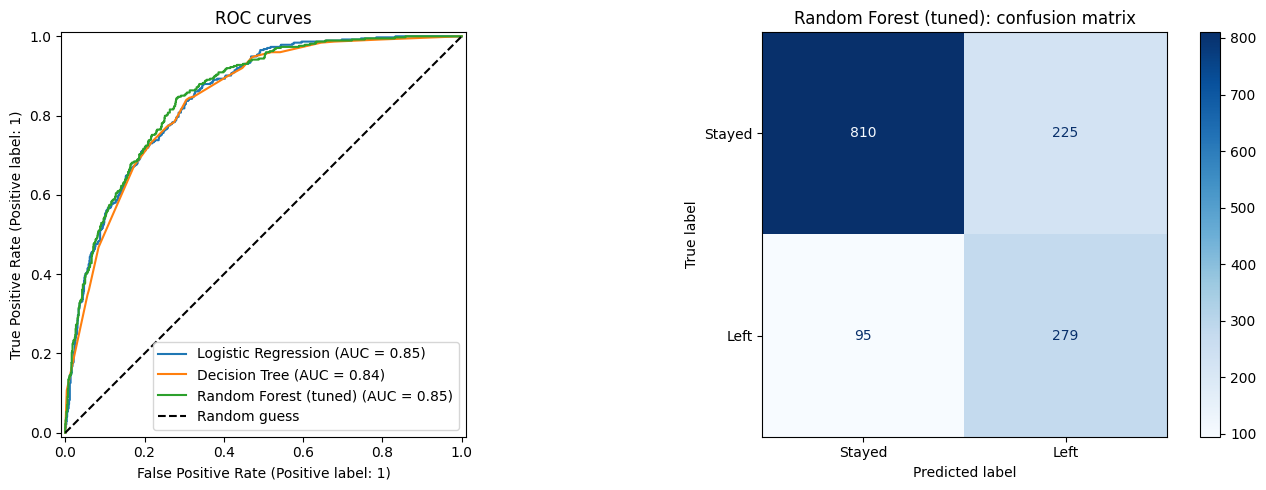

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, pipe in final_models.items():
    RocCurveDisplay.from_estimator(pipe, X_test, y_test, name=name, ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_title("ROC curves")
axes[0].legend()

ConfusionMatrixDisplay.from_estimator(
    best_rf, X_test, y_test,
    display_labels=["Stayed", "Left"], cmap="Blues", ax=axes[1]
)
axes[1].set_title("Random Forest (tuned): confusion matrix")

plt.tight_layout()
plt.show()

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["roc_auc", "f1", "recall", "precision"]

rows = []
for name, pipe in final_models.items():
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    row = {"Model": name}
    for m in scoring:
        vals = s[f"test_{m}"]
        row[m] = f"{vals.mean():.3f} ± {vals.std():.3f}"
    rows.append(row)

pd.DataFrame(rows).set_index("Model")

,roc_auc,f1,recall,precision
Model,,,,
Logistic Regression,0.859 ± 0.012,0.640 ± 0.021,0.810 ± 0.034,0.529 ± 0.020
Decision Tree,0.845 ± 0.008,0.629 ± 0.007,0.813 ± 0.022,0.514 ± 0.014
Random Forest (tuned),0.860 ± 0.008,0.648 ± 0.021,0.751 ± 0.030,0.571 ± 0.021


In [59]:
ohe = best_lr = pipelines_bal["Logistic Regression"]
feature_names = ohe.named_steps["prep"].get_feature_names_out()
coefs = ohe.named_steps["model"].coef_[0]

coef_data = pd.DataFrame({"feature": feature_names, "coef": coefs})
coef_data["abs_coef"] = coef_data["coef"].abs()
coef_data.sort_values("abs_coef", ascending=False).head(12)[["feature", "coef"]]

,feature,coef
0,num__Tenure Months,-1.209694
10,cat__Dependents_Yes,-0.930744
39,cat__Contract_Two year,-0.754424
9,cat__Dependents_No,0.703389
37,cat__Contract_Month-to-month,0.660048
17,cat__Internet Service_Fiber optic,0.586088
16,cat__Internet Service_DSL,-0.558362
1,num__Monthly Charges,-0.551369
2,num__Total Charges,0.515836
40,cat__Paperless Billing_No,-0.273652
